# Hash10 vs. Grover: classical search and IBM quantum hardware

**Project:** A reproducible, small-scale *quantum preimage search* experiment.  
**Default:** local/offline only; no IBM job is submitted unless you explicitly enable it.  
**Targets:** Hash10 (10-bit input and output) for the ideal comparison; Hash3/Hash4 for initial real-QPU trials.

### What this experiment does **and does not** establish
- `HashN` is our own **non-cryptographic, SHA-inspired toy mixing function**. It is **not** SHA-256 truncated to N bits, and does not provide SHA-like security.
- The quantum phase oracle **actually computes HashN reversibly**, compares its output to the chosen target and *uncomputes* the hash. It is not a hardcoded secret-state oracle.
- The classical baseline deliberately uses brute-force oracle queries. Because HashN's formula is public and highly structured, other classical techniques may outperform brute force.
- A 10-bit ideal Grover simulation here uses an **effective 1,024-element amplitude vector**, not a full 28-qubit simulation. The full reversible Hash10 circuit is constructed but is generally too deep for today's noisy hardware.
- A quantum *iteration* contains one phase oracle, which computes HashN **forward and backward**, plus the costly diffusion operator. Query counts are not wall-clock speedups.

**Read first:** IBM's Grover tutorial says deep multi-controlled-gate circuits become impractical on noisy physical processors. Open Plan offers 10 minutes per rolling 28 days, and **does not support IBM's QPU dry-run feature**.

Sources: [IBM Grover tutorial](https://quantum.cloud.ibm.com/docs/en/tutorials/grovers-algorithm), [IBM Open Plan](https://quantum.cloud.ibm.com/docs/en/guides/plans-overview), [IBM dry-run limits](https://quantum.cloud.ibm.com/docs/en/guides/dry-run-jobs), [IBM Sampler](https://quantum.cloud.ibm.com/docs/en/guides/get-started-with-sampler).

## 1. Installation

In your active Jupyter/Python virtual environment, install:

```bash
python -m pip install 'qiskit>=2.3' 'qiskit-ibm-runtime>=0.51' matplotlib pandas
```

Restart your notebook kernel after installation. No IBM credentials are needed for the local sections.

In [2]:
%pip install "qiskit>=2.3" "qiskit-ibm-runtime>=0.51"

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ------- -------------------------------- 1.8/9.3 MB 9.7 MB/s eta 0:00:01
   --------------------- ------------------ 5.0/9.3 MB 13.0 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 15.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 2.0/2.0 MB 24.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---------------------------------------- 2.3/2.3 MB 31.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/541.5 kB ? eta -:--:--
   --------------------------------------- 541.5/541.5 kB 20.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---------------------------------------- 2.3/2.3 MB 32.4 MB/s eta 0:00:00
   -------------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
botocore 1.42.69 requires python-dateutil<3.0.0,>=2.1, but you have python-dateutil 3.0.0 which is incompatible.
aiobotocore 2.19.0 requires botocore<1.36.4,>=1.36.0, but you have botocore 1.42.69 which is incompatible.
aiobotocore 2.19.0 requires python-dateutil<3.0.0,>=2.1, but you have python-dateutil 3.0.0 which is incompatible.


In [1]:
from importlib.metadata import version

print("Qiskit:", version("qiskit"))
print("IBM Runtime:", version("qiskit-ibm-runtime"))

from qiskit import QuantumCircuit
from qiskit_ibm_runtime import QiskitRuntimeService

print("Quantum environment ready!")

Qiskit: 2.6.2
IBM Runtime: 0.51.0
Quantum environment ready!


In [3]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()

backends = service.backends(
    simulator=False,
    operational=True
)

print(f"Connected! Found {len(backends)} physical QPUs.\n")

for backend in backends:
    print(
        f"{backend.name}: "
        f"{backend.num_qubits} qubits"
    )

backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=10
)

print("\nSelected processor:", backend.name)
print("Physical qubits:", backend.num_qubits)

Connected! Found 3 physical QPUs.

ibm_fez: 156 qubits
ibm_kingston: 156 qubits
ibm_marrakesh: 156 qubits

Selected processor: ibm_marrakesh
Physical qubits: 156


In [5]:
import math
import random
import json
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector

print('Local dependencies loaded. IBM account not required yet.')

Local dependencies loaded. IBM account not required yet.


## 2. Define the non-cryptographic HashN function

For each output bit, compute the XOR of two neighboring input bits and a nonlinear AND of two other bits (indices wrap around):

$$h_i = x_i \oplus x_{i+1} \oplus (x_{i+2} \land x_{i+3}).$$

The output length is N bits; inputs are numbered **least-significant bit first**. HashN is deterministic, nonlinear, and cheap to implement reversibly with CNOT and Toffoli. It has collisions for most sizes. We select a target output that happens to have exactly one preimage so the basic Grover analysis is clean.

**Scientific caveat:** choosing a unique target requires tabulating the toy hash once (offline ground truth). This makes the experiment transparent and falsifiable; it is **not** evidence of practical cryptographic security.

In [6]:
def hash_n(value: int, n: int) -> int:
    if n < 3 or not 0 <= value < (1 << n):
        raise ValueError('n >= 3 and input must fit n bits')
    bits = [(value >> i) & 1 for i in range(n)]
    out = [bits[i] ^ bits[(i + 1) % n] ^
           (bits[(i + 2) % n] & bits[(i + 3) % n]) for i in range(n)]
    return sum(bit << i for i, bit in enumerate(out))


def define_problem(n: int):
    preimages = defaultdict(list)
    for x in range(1 << n):
        preimages[hash_n(x, n)].append(x)
    unique_targets = sorted(y for y, matches in preimages.items() if len(matches) == 1)
    if not unique_targets:
        raise ValueError(f'No unique-preimage outputs for n={n}')
    target = unique_targets[len(unique_targets)//2]  # fixed, deterministic choice
    secret = preimages[target][0]
    return {'n': n, 'target': target, 'secret': secret,
            'unique_targets': len(unique_targets),
            'covered_outputs': len(preimages)}


problems = {n: define_problem(n) for n in range(3, 11)}
rows = []
for n, p in problems.items():
    rows.append({'bits': n, 'candidates': 1 << n,
                 'unique_target_outputs': p['unique_targets'],
                 'target_bits': format(p['target'], f'0{n}b'),
                 'preimage_bits': format(p['secret'], f'0{n}b')})
display(pd.DataFrame(rows))

p10 = problems[10]
assert hash_n(p10['secret'], 10) == p10['target']
print(f"Hash10 target: {p10['target']:010b}, matching input: {p10['secret']:010b}")

,bits,candidates,unique_target_outputs,target_bits,preimage_bits
0,3,8,8,100,011
1,4,16,8,1011,1100
2,5,32,12,10000,10111
3,6,64,25,100100,011011
4,7,128,72,0111000,1111011
5,8,256,116,10000011,11101100
6,9,512,248,100010011,111000010
7,10,1024,466,1000011110,0111001011


Hash10 target: 1000011110, matching input: 0111001011


## 3. Classical random-order search baseline

For a unique matching input, randomly permuting and testing all $2^n$ inputs needs $(2^n+1)/2$ hash evaluations **on average**. This benchmark measures only the prescribed brute-force method.

Hash10 brute force: observed 514.06 trials on average
Hash10 brute force: theoretical 512.50 trials on average


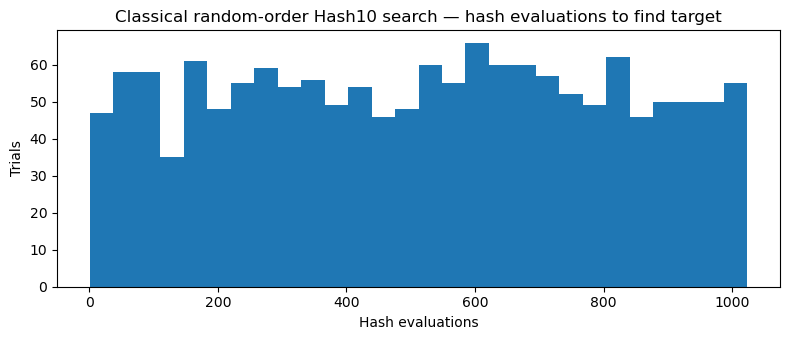

In [7]:
def classical_search_trials(problem, trials=1500, seed=2026):
    n, target = problem['n'], problem['target']
    rng = random.Random(seed)
    candidates = list(range(1 << n))
    steps = []
    for _ in range(trials):
        rng.shuffle(candidates)
        for count, x in enumerate(candidates, start=1):
            if hash_n(x, n) == target:
                steps.append(count)
                break
        else:
            raise AssertionError('Expected a matching input')
    return steps

classical10 = classical_search_trials(p10)
print(f"Hash10 brute force: observed {sum(classical10)/len(classical10):.2f} trials on average")
print(f"Hash10 brute force: theoretical {(2**10+1)/2:.2f} trials on average")

plt.figure(figsize=(8, 3.5))
plt.hist(classical10, bins=28)
plt.title('Classical random-order Hash10 search — hash evaluations to find target')
plt.xlabel('Hash evaluations')
plt.ylabel('Trials')
plt.tight_layout()
plt.show()

## 4. Ideal Grover search (effective N-dimensional amplitude simulation)

We simulate Grover's ideal **logical** action on the $2^n$ possible inputs: flip phases of all states matching the target, then reflect the amplitude vector around its average. This uses only $2^n$ amplitudes, avoiding the much larger state vector required to simulate all the ancilla qubits in the reversible implementation. The physical gate implementation comes next.

For a unique target, the ideal success probability after $k$ iterations is

$$P(k)=\sin^2\left((2k+1)\arcsin(1/\sqrt{2^n})ight).$$

Ideal Hash10: best Grover iterations = 25
Ideal single-shot probability = 99.946124%
Oracle phase flips = 25; forward+reverse hash computations inside those oracles = 50


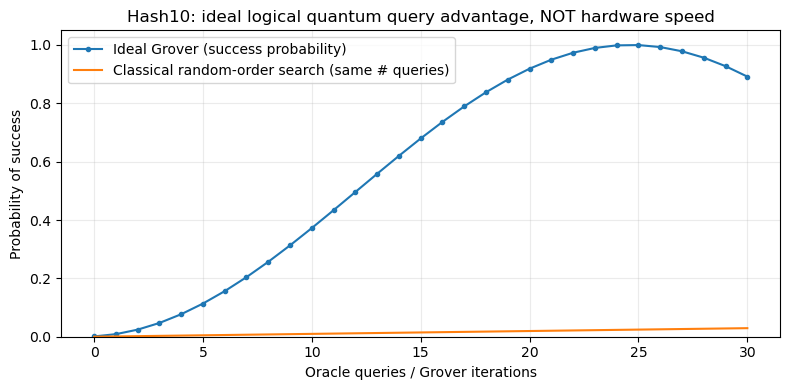

In [8]:
def ideal_grover_curve(problem, max_iterations=None):
    n, target = problem['n'], problem['target']
    N = 1 << n
    max_iterations = max_iterations or math.ceil(math.pi/4 * math.sqrt(N)) + 4
    matches = {x for x in range(N) if hash_n(x, n) == target}
    assert len(matches) == 1
    amp = [1.0/math.sqrt(N)] * N
    data = []
    for k in range(max_iterations + 1):
        success = sum(amp[i]**2 for i in matches)
        data.append({'iterations':k, 'success':success,
                     'classical_success_after_same_number_of_queries': min(1., k/N)})
        if k == max_iterations:
            break
        for i in matches:
            amp[i] = -amp[i]
        mean = sum(amp)/N
        amp = [2*mean - a for a in amp]
    return pd.DataFrame(data)

ideal10 = ideal_grover_curve(p10)
optimal_k10 = int(ideal10.loc[ideal10.success.idxmax(), 'iterations'])
print(f"Ideal Hash10: best Grover iterations = {optimal_k10}")
print(f"Ideal single-shot probability = {ideal10.success.max():.6%}")
print(f"Oracle phase flips = {optimal_k10}; forward+reverse hash computations inside those oracles = {2*optimal_k10}")

plt.figure(figsize=(8, 4))
plt.plot(ideal10.iterations, ideal10.success, marker='.', label='Ideal Grover (success probability)')
plt.plot(ideal10.iterations, ideal10.classical_success_after_same_number_of_queries,
         label='Classical random-order search (same # queries)')
plt.xlabel('Oracle queries / Grover iterations')
plt.ylabel('Probability of success')
plt.title('Hash10: ideal logical quantum query advantage, NOT hardware speed')
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Construct the **real** reversible HashN Grover oracle

Qubit registers:
- `x`: N input qubits, initially in a uniform superposition.
- `h`: N scratch output qubits, initially $|0angle$.
- `a`: N-2 ancilla qubits, used to implement the multi-controlled phase check with a Toffoli ladder.

**Hash10 therefore uses 28 physical qubits, not 10.** Every phase oracle computes all HashN output bits using CNOT/Toffoli, compares the entire result to the public target, and uncomputes all scratch. The diffusion operation also needs a multi-controlled phase check. Large N and repeated iterations become very deep very quickly.

Because HashN is calculated from the quantum input register rather than supplying the answer, this is a real reversible hash-comparison oracle.

In [9]:
def apply_hash(qc, x, h, n, reverse=False):
    """XOR HashN(x) into h, or uncompute using reversed self-inverse gates."""
    for i in (reversed(range(n)) if reverse else range(n)):
        if reverse:
            qc.ccx(x[(i+2) % n], x[(i+3) % n], h[i])
            qc.cx(x[(i+1) % n], h[i])
            qc.cx(x[i], h[i])
        else:
            qc.cx(x[i], h[i])
            qc.cx(x[(i+1) % n], h[i])
            qc.ccx(x[(i+2) % n], x[(i+3) % n], h[i])


def phase_if_all_ones(qc, controls, anc):
    """Apply -1 phase exactly when all control qubits are |1>; ancillas return to |0>."""
    n = len(controls)
    if n < 3 or len(anc) < n - 2:
        raise ValueError('need at least 3 controls and n-2 zeroed ancillas')
    qc.ccx(controls[0], controls[1], anc[0])
    for i in range(2, n-1):
        qc.ccx(anc[i-2], controls[i], anc[i-1])
    qc.cz(anc[n-3], controls[n-1])
    for i in reversed(range(2, n-1)):
        qc.ccx(anc[i-2], controls[i], anc[i-1])
    qc.ccx(controls[0], controls[1], anc[0])


def apply_hash_oracle(qc, x, h, anc, n, target):
    """Phase-mark exactly those inputs for which HashN(x) == target."""
    apply_hash(qc, x, h, n)
    for i in range(n):
        if not ((target >> i) & 1):
            qc.x(h[i])
    phase_if_all_ones(qc, h, anc)
    for i in range(n):
        if not ((target >> i) & 1):
            qc.x(h[i])
    apply_hash(qc, x, h, n, reverse=True)


def apply_diffuser(qc, x, anc):
    """Diffusion around initial uniform state, up to a global phase."""
    qc.h(x)
    qc.x(x)
    phase_if_all_ones(qc, x, anc)
    qc.x(x)
    qc.h(x)


def grover_circuit(problem, iterations, measure=True):
    n = problem['n']
    x = QuantumRegister(n, 'x')
    h = QuantumRegister(n, 'h')
    anc = QuantumRegister(n-2, 'a')
    if measure:
        readout = ClassicalRegister(n, 'readout')
        qc = QuantumCircuit(x, h, anc, readout)
    else:
        qc = QuantumCircuit(x, h, anc)
    qc.h(x)
    for _ in range(iterations):
        apply_hash_oracle(qc, x, h, anc, n, problem['target'])
        apply_diffuser(qc, x, anc)
    if measure:
        qc.measure(x, readout)
    return qc

for n in [3, 4, 5, 10]:
    k = round(math.pi / (4 * math.asin(1 / math.sqrt(2**n))) - 0.5)
    qc = grover_circuit(problems[n], k)
    print(f'Hash{n}: {qc.num_qubits} physical qubits, {k} iterations, '
          f'pre-transpilation depth {qc.depth()}, high-level gates {sum(qc.count_ops().values())}')

Hash3: 7 physical qubits, 2 iterations, pre-transpilation depth 46, high-level gates 86
Hash4: 10 physical qubits, 3 iterations, pre-transpilation depth 86, high-level gates 164
Hash5: 13 physical qubits, 4 iterations, pre-transpilation depth 138, high-level gates 298
Hash10: 28 physical qubits, 25 iterations, pre-transpilation depth 1602, high-level gates 3620


## 6. Verify the full gate-level circuit on *small* instances

Use Qiskit's state-vector calculation to verify that the output and work registers return to zero and that the right input is amplified. The **full** 28-qubit state vector for Hash10 would require at least 4 GiB just for the complex amplitudes, and its deep gate simulation can be computationally costly. We intentionally do not perform that simulation.

This small-instance test is independent of the analytical approximation above: it executes every CNOT, Toffoli, phase check and diffusion operation.

In [10]:
def verify_small_circuit(n):
    p = problems[n]
    curve = ideal_grover_curve(p)
    optimal_k = int(curve.loc[curve.success.idxmax(), 'iterations'])
    qc = grover_circuit(p, optimal_k, measure=False)
    sv = Statevector.from_instruction(qc)
    # x is the least-significant register; clean scratch registers mean basis index == x.
    measured_target_prob = float(abs(sv.data[p['secret']])**2)
    ideal_target_prob = float(curve.success.max())
    scratch_leak = 1 - sum(abs(sv.data[i])**2 for i in range(1 << n))
    assert abs(measured_target_prob - ideal_target_prob) < 1e-8
    assert abs(scratch_leak) < 1e-8
    print(f'Hash{n} — {optimal_k} Grover iterations — '
          f'gate-level success {measured_target_prob:.6%}; '
          f'ideal logical success {ideal_target_prob:.6%}; '
          f'unclean scratch probability {scratch_leak:.2e}')

verify_small_circuit(3)
verify_small_circuit(4)
# Optionally enable after the quick tests:
# verify_small_circuit(5)

Hash3 — 6 Grover iterations — gate-level success 99.978638%; ideal logical success 99.978638%; unclean scratch probability 6.77e-15
Hash4 — 3 Grover iterations — gate-level success 96.131897%; ideal logical success 96.131897%; unclean scratch probability 4.88e-15


## 7. IBM hardware: **compile and inspect locally**, without submitting a job

First create an [IBM Quantum Open Plan](https://quantum.cloud.ibm.com/) account. Install the dependencies in Section 1 and save your API credentials **locally once** (do not paste a token into the notebook; use `getpass`).

The instance must be an **Open Plan** instance. Find its CRN on the IBM Quantum Instances page; do not accidentally select a paid instance. IBM Open Plan is in `us-east`. You can inspect your available backend and transpiled two-qubit depth without spending QPU time.

⚠️ **Do not assume that transpiling a circuit means it will execute with high fidelity.** A compilation can succeed even when the circuit is too noisy to recover the input.

In [ ]:
# RUN MANUALLY ONCE, after setting your Open instance CRN:
# from getpass import getpass
# from qiskit_ibm_runtime import QiskitRuntimeService
# OPEN_INSTANCE_CRN = 'paste your Open Plan instance CRN here'
# QiskitRuntimeService.save_account(
#     token=getpass('IBM Quantum API key: '),
#     instance=OPEN_INSTANCE_CRN,
#     channel='ibm_quantum_platform',
#     set_as_default=True,
# )

# This cell DOES NOT save credentials or contact IBM.

In [25]:
# Hardware preflight: set to True only when you are ready to connect.
CONNECT_TO_IBM = True
HARDWARE_N = 4
ITERATIONS_TO_TEST = [0, 1]
SHOTS = 2048

backend = None
transpiled_circuits = []
compiled_depths = []

if CONNECT_TO_IBM:
    if not OPEN_INSTANCE_CRN:
        raise ValueError('Enter your Open Plan CRN before connecting')
    if HARDWARE_N not in (3, 4, 5, 6, 7, 8, 9, 10):
        raise ValueError('Unsupported bit size')
    from qiskit_ibm_runtime import QiskitRuntimeService
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    service = QiskitRuntimeService(instance=OPEN_INSTANCE_CRN)
    backend = service.least_busy(operational=True, simulator=False,
                                 min_num_qubits=3*HARDWARE_N-2)
    print('Hardware backend:', backend.name)
    pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
    for k in ITERATIONS_TO_TEST:
        logical = grover_circuit(problems[HARDWARE_N], k)
        compiled = pm.run(logical)
        d2 = compiled.depth(lambda inst: inst.operation.num_qubits == 2)
        transpiled_circuits.append(compiled)
        compiled_depths.append(d2)
        print(f'iterations={k}: qubits={logical.num_qubits}, '
              f'2Q depth={d2}, size={compiled.size()}, '
              f'2Q gates={sum(count for op, count in compiled.count_ops().items() if op in ("cx","cz","ecr","rzz"))}')
    rough_seconds = 2 + 0.00035 * (SHOTS * len(transpiled_circuits))
    print(f'IBM rough baseline usage estimate: ~{rough_seconds:.2f} sec; '
          'deep circuits may take longer. This is NOT a reliable quote.')
else:
    print('Offline only: set CONNECT_TO_IBM=True when credentials are ready.')

Hardware backend: ibm_marrakesh
iterations=0: qubits=10, 2Q depth=0, size=16, 2Q gates=0
iterations=1: qubits=10, 2Q depth=173, size=1006, 2Q gates=244
IBM rough baseline usage estimate: ~3.43 sec; deep circuits may take longer. This is NOT a reliable quote.


In [24]:
from pathlib import Path
import shutil

source = Path("hash10_hardware_results.json")

if source.exists():
    shutil.copy2(
        source,
        "hash8_marrakesh_results.json"
    )

## 8. Execute a physical QPU job — only with **explicit opt-in**

IBM's current client-side `Sampler` requires `qiskit-ibm-runtime>=0.50`. The Open Plan supports job mode, not sessions. **The `dry_run=True` feature is not available to Open Plan accounts**, so we use only local preflight and a small real run after explicit opt-in. The QPU measures only `x`, and the code records per-iteration target success, job ID and QPU usage.

**Safety gates:** set `SUBMIT_REAL_QPU_JOB=True` and inspect your compiled depths first. If any depth exceeds `MAX_2Q_DEPTH`, the notebook will refuse to submit unless you explicitly override the depth limit. Use a few hundred shots per circuit first; the IBM platform tracks exact usage.

If you want to expand beyond the first run, change `HARDWARE_N` to 4 and set `ITERATIONS_TO_TEST=[0,1,2,3]`. The 10-bit, 25-iteration full-hash circuit is **not** recommended for real hardware in this era.

In [26]:
SUBMIT_REAL_QPU_JOB = True  # Safe default! Set True only when ready.
MAX_2Q_DEPTH = 700
OVERRIDE_DEPTH_LIMIT = False

hardware_results = []
if SUBMIT_REAL_QPU_JOB:
    if not CONNECT_TO_IBM or backend is None or not transpiled_circuits:
        raise RuntimeError('First connect and compile the circuits in Section 7')
    if any(d > MAX_2Q_DEPTH for d in compiled_depths) and not OVERRIDE_DEPTH_LIMIT:
        raise RuntimeError(f'At least one circuit exceeds {MAX_2Q_DEPTH} two-qubit layers. '
                           'Reduce iterations/size or deliberately override.')
    from qiskit_ibm_runtime.executor_sampler import Sampler
    sampler = Sampler(mode=backend)  # Job mode; permitted on the Open Plan
    job = sampler.run(transpiled_circuits, shots=SHOTS)  # A REAL QPU submission
    print('Submitted real IBM job:', job.job_id())
    result = job.result()
    for k, pub in zip(ITERATIONS_TO_TEST, result):
        counts = pub.data.readout.get_counts()
        secret_str = format(problems[HARDWARE_N]['secret'], f'0{HARDWARE_N}b')
        hit = counts.get(secret_str, 0)
        hardware_results.append({
            'bits': HARDWARE_N,
            'iterations': k,
            'target': format(problems[HARDWARE_N]['target'], f'0{HARDWARE_N}b'),
            'expected_preimage': secret_str,
            'hits': hit, 'shots': sum(counts.values()),
            'success_rate': hit/sum(counts.values()),
            'backend': backend.name, 'job_id': job.job_id(),
            'counts': counts,
        })
    print('Actual QPU usage (seconds):', job.usage())
    display(pd.DataFrame(hardware_results).drop(columns='counts'))
    Path('hash10_hardware_results.json').write_text(json.dumps(hardware_results, indent=2))
    print('Saved actual measurements to hash10_hardware_results.json')
else:
    print('No QPU job submitted. Submit only after reviewing the compiled circuit.')

Submitted real IBM job: dbn48544148s73909mcg
Actual QPU usage (seconds): 0


,bits,iterations,target,expected_preimage,hits,shots,success_rate,backend,job_id
0,4,0,1011,1100,125,2048,0.061035,ibm_marrakesh,dbn48544148s73909mcg
1,4,1,1011,1100,136,2048,0.066406,ibm_marrakesh,dbn48544148s73909mcg


Saved actual measurements to hash10_hardware_results.json


In [17]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()
job = service.job("dbn3ei8ou4as73b3qa20")

print("Status:", job.status())
print("QPU usage (seconds):", job.usage())
print("Usage metadata:", job.metrics().get("usage"))

Status: DONE
QPU usage (seconds): 3
Usage metadata: {'qpu_charge_time_seconds': 3, 'value': 0.035459, 'unit': 'resource_units', 'status': 'complete', 'details': [{'value': 0.035459, 'unit': 'resource_units', 'metric': {'id': 'caffe3ca-729c-5750-8777-df63bbf8bfd9', 'value': 3}}]}


In [18]:
def marked_state_control(problem, iterations=1):
    n = problem["n"]
    secret = problem["secret"]

    x = QuantumRegister(n, "x")
    anc = QuantumRegister(n - 2, "a")
    readout = ClassicalRegister(n, "readout")
    qc = QuantumCircuit(x, anc, readout)

    qc.h(x)

    for _ in range(iterations):
        # Mark the known correct input directly
        for i in range(n):
            if not ((secret >> i) & 1):
                qc.x(x[i])

        phase_if_all_ones(qc, x, anc)

        for i in range(n):
            if not ((secret >> i) & 1):
                qc.x(x[i])

        apply_diffuser(qc, x, anc)

    qc.measure(x, readout)
    return qc


from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)

control = marked_state_control(problems[8], 1)

pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=3
)

compiled_control = pm.run(control)

print("Control qubits:", control.num_qubits)
print("Total gates:", compiled_control.size())
print(
    "Two-qubit depth:",
    compiled_control.depth(
        lambda inst: inst.operation.num_qubits == 2
    )
)

Control qubits: 14
Total gates: 1069
Two-qubit depth: 211


In [19]:
import numpy as np
from qiskit.quantum_info import Statevector

n = 8
secret = problems[n]["secret"]

sv = Statevector.from_instruction(
    control.remove_final_measurements(inplace=False)
)

ideal_probability = float(
    sv.probabilities(qargs=list(range(n)))[secret]
)

theoretical_probability = float(
    np.sin(3 * np.arcsin(1 / np.sqrt(2**n)))**2
)

print("Target:", format(secret, "08b"))
print("Simulated success:", ideal_probability)
print("Theoretical success:", theoretical_probability)

assert np.isclose(
    ideal_probability, theoretical_probability, atol=1e-9
)

Target: 11101100
Simulated success: 0.03479099273681628
Theoretical success: 0.034790992736816406


In [21]:
from qiskit_ibm_runtime import SamplerV2 as Sampler
import json

RUN_CONTROL_QPU = True  # Change to True to submit

if RUN_CONTROL_QPU:
    sampler = Sampler(mode=backend)
    job = sampler.run([compiled_control], shots=2048)

    print("Job ID:", job.job_id())

    result = job.result()
    counts = result[0].data.readout.get_counts()

    secret_bits = format(secret, "08b")
    hits = counts.get(secret_bits, 0)
    shots = sum(counts.values())

    print("Backend:", backend.name)
    print("Expected input:", secret_bits)
    print("Correct recoveries:", hits)
    print("Total shots:", shots)
    print("Success rate:", f"{hits / shots:.4%}")

    with open("hash8_control_results.json", "w") as f:
        json.dump({
            "backend": backend.name,
            "job_id": job.job_id(),
            "bits": 8,
            "iterations": 1,
            "target_preimage": secret_bits,
            "shots": shots,
            "hits": hits,
            "counts": counts
        }, f, indent=2)

    print("Results saved.")

C:\Users\fixin\AppData\Local\Temp\ipykernel_46540\2271202291.py:7: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Job ID: dbn3soc4148s73909810
Backend: ibm_marrakesh
Expected input: 11101100
Correct recoveries: 12
Total shots: 2048
Success rate: 0.5859%
Results saved.


In [22]:
from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)
import pandas as pd

pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=3,
    seed_transpiler=42
)

rows = []

for n in range(4, 9):
    qc = grover_circuit(problems[n], 1)
    compiled = pm.run(qc)

    depth_2q = compiled.depth(
        lambda inst: inst.operation.num_qubits == 2
    )

    gates_2q = sum(
        inst.operation.num_qubits == 2
        for inst in compiled.data
    )

    rows.append({
        "Hash": f"Hash{n}",
        "Candidates": 2**n,
        "Qubits": qc.num_qubits,
        "2Q Depth": depth_2q,
        "2Q Gates": gates_2q
    })

display(pd.DataFrame(rows))

,Hash,Candidates,Qubits,2Q Depth,2Q Gates
0,Hash4,16,10,163,238
1,Hash5,32,13,229,382
2,Hash6,64,16,281,503
3,Hash7,128,19,312,620
4,Hash8,256,22,436,823


## 9. Compare measured and ideal success rates

Run this after receiving real results. A measured output probability above the random baseline is the first milestone; achieving the ideal amplification peak on larger N is significantly harder. For an N-bit unique-preimage search, the uniform random baseline is $1/2^N$.

In [ ]:
if hardware_results:
    n = HARDWARE_N
    ideal = ideal_grover_curve(problems[n], max_iterations=max(ITERATIONS_TO_TEST))
    actual = pd.DataFrame(hardware_results)
    plt.figure(figsize=(8, 4))
    plt.plot(ideal.iterations, ideal.success, 'o-', label='Ideal Grover')
    plt.plot(actual.iterations, actual.success_rate, 's-', label='Measured IBM QPU')
    plt.axhline(1/(2**n), linestyle='--', label='Uniform random baseline')
    plt.ylim(0, 1.05)
    plt.xlabel('Grover iterations')
    plt.ylabel('Probability of recovering input')
    plt.title(f'Hash{n}: IBM QPU versus ideal quantum theory')
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print('No physical results to graph yet. The ideal 10-bit curve is shown in Section 4.')

## 10. Suggested protocol and interpretation

1. **Local:** Run Sections 1–6. Verify Hash10's unique target, classical baseline, and ideal 25-iteration Grover result.
2. **Quantum circuit:** Verify the full Hash3 and Hash4 gate-level simulations. The output and ancilla registers must return to zero.
3. **Compile only:** Connect to IBM with your **Open Plan instance CRN**, compile Hash3 circuits at 0, 1, and 2 iterations, and read the reported two-qubit depth.
4. **QPU pilot:** Enable actual submission for 512 shots each at Hash3 (0, 1, 2 iterations). Save the job ID and exact QPU time.
5. **Stretch:** If Hash3 demonstrates meaningful amplification, attempt Hash4 (0–3 iterations). If it does not, focus on improving gate layout or using a less expensive toy mixing circuit; don't increase N blindly.
6. **Hash10:** Keep as the full 1,024-candidate benchmark. The ideal logical speedup is meaningful, but **do not call it a practical quantum speedup**, and don't claim this defeats a real-world cryptographic hash.

**Useful distinctions for a report:** `classical hash evaluations` vs `quantum oracle calls` vs `forward+reverse hash evaluations` vs `compiled two-qubit gate depth` vs `measured probability` vs `actual billed QPU seconds` vs `elapsed wall time`. These measure very different things.

### Known limitations
- HashN is a toy, not a secure hash. A specialized classical inverter could outperform our brute-force baseline.
- We preselect a uniquely solvable target by exhaustive enumeration to make theoretical comparisons unambiguous.
- IBM Open Plan does **not** offer no-charge dry-run jobs. Preflight is local and necessarily approximate.
- The provided code was structurally prepared and the classical hash mathematics were checked; it must still be executed in a local environment with the specified Qiskit packages before relying on it for a live IBM submission.

**Documentation:** [IBM Open Plan](https://quantum.cloud.ibm.com/docs/en/guides/plans-overview) · [Grover](https://quantum.cloud.ibm.com/docs/en/tutorials/grovers-algorithm) · [Client-side Sampler](https://quantum.cloud.ibm.com/docs/en/guides/get-started-with-sampler) · [Usage estimates](https://quantum.cloud.ibm.com/docs/en/guides/estimate-job-run-time).

In [27]:
import math
from qiskit.quantum_info import Statevector

for n in (3, 4):
    problem = problems[n]
    qc = grover_circuit(problem, 1, measure=False)

    sv = Statevector.from_instruction(qc)
    distribution = sv.probabilities(qargs=list(range(n)))

    actual = float(distribution[problem["secret"]])
    theoretical = math.sin(
        3 * math.asin(1 / math.sqrt(2**n))
    ) ** 2

    print(f"\nHash{n}")
    print(f"Simulated success: {actual:.4%}")
    print(f"Theoretical success: {theoretical:.4%}")

    assert abs(actual - theoretical) < 1e-8

print("\nBoth quantum circuits verified.")


Hash3
Simulated success: 78.1250%
Theoretical success: 78.1250%

Hash4
Simulated success: 47.2656%
Theoretical success: 47.2656%

Both quantum circuits verified.


In [28]:
from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)

qc = marked_state_control(problems[4], 1)

pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=3,
    seed_transpiler=42
)

compiled = pm.run(qc)

print("Backend:", backend.name)
print("Qubits:", qc.num_qubits)
print("Total gates:", compiled.size())
print("2Q gates:", sum(
    inst.operation.num_qubits == 2
    for inst in compiled.data
))
print("2Q depth:", compiled.depth(
    lambda inst: inst.operation.num_qubits == 2
))

Backend: ibm_marrakesh
Qubits: 6
Total gates: 358
2Q gates: 78
2Q depth: 69


In [29]:
import numpy as np
from qiskit.quantum_info import Statevector

problem = problems[4]
secret = problem["secret"]

circuits = {
    "Full Hash4": grover_circuit(problem, 1, measure=False),
    "Hash4 control": marked_state_control(
        problem, 1
    ).remove_final_measurements(inplace=False)
}

expected = 0.47265625

for name, qc in circuits.items():
    sv = Statevector.from_instruction(qc)
    success = sv.probabilities(qargs=list(range(4)))[secret]

    print(f"{name}: {success:.4%}")
    assert np.isclose(success, expected, atol=1e-8)

print("Both circuits verified!")

Full Hash4: 47.2656%
Hash4 control: 47.2656%
Both circuits verified!


In [30]:
from qiskit_ibm_runtime.executor_sampler import Sampler
import json

RUN_HASH4_CONTROL = True  # Set True to submit

if RUN_HASH4_CONTROL:
    sampler = Sampler(mode=backend)

    job = sampler.run([compiled], shots=2048)
    print("Job submitted:", job.job_id())

    result = job.result()
    counts = result[0].data.readout.get_counts()

    secret_bits = format(problems[4]["secret"], "04b")
    hits = counts.get(secret_bits, 0)
    shots = sum(counts.values())

    print("Correct input:", secret_bits)
    print("Hits:", hits)
    print("Shots:", shots)
    print("Success rate:", f"{hits / shots:.2%}")

    with open("hash4_control_results.json", "w") as f:
        json.dump({
            "backend": backend.name,
            "job_id": job.job_id(),
            "experiment": "Hash4 direct marking",
            "shots": shots,
            "hits": hits,
            "counts": counts
        }, f, indent=2)

Job submitted: dbn4dqgou4as73b3rkmg
Correct input: 1100
Hits: 498
Shots: 2048
Success rate: 24.32%


In [31]:
import math
import pandas as pd
from qiskit.quantum_info import Statevector
from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)

pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=3,
    seed_transpiler=42
)

control_compiled = {}
rows = []

for n in [5, 6, 7]:
    problem = problems[n]
    qc = marked_state_control(problem, 1)

    # Verify exact ideal quantum behavior
    sv = Statevector.from_instruction(
        qc.remove_final_measurements(inplace=False)
    )

    ideal = math.sin(
        3 * math.asin(1 / math.sqrt(2**n))
    ) ** 2

    simulated = float(
        sv.probabilities(qargs=list(range(n)))[
            problem["secret"]
        ]
    )

    assert abs(simulated - ideal) < 1e-8

    compiled = pm.run(qc)
    control_compiled[n] = compiled

    rows.append({
        "Hash": f"Hash{n}",
        "Candidates": 2**n,
        "Qubits": qc.num_qubits,
        "2Q Depth": compiled.depth(
            lambda inst: inst.operation.num_qubits == 2
        ),
        "2Q Gates": sum(
            inst.operation.num_qubits == 2
            for inst in compiled.data
        ),
        "Ideal Success": f"{ideal:.2%}"
    })

display(pd.DataFrame(rows))

,Hash,Candidates,Qubits,2Q Depth,2Q Gates,Ideal Success
0,Hash5,32,8,103,119,25.83%
1,Hash6,64,10,147,170,13.48%
2,Hash7,128,12,177,207,6.89%


In [32]:
from qiskit_ibm_runtime.executor_sampler import Sampler
import json
import math
from datetime import datetime, timezone

SHOTS = 2048
RUN_QPU = True  # Change to True to submit

experiments = []

for n in [5, 6]:
    baseline = pm.run(marked_state_control(problems[n], 0))

    experiments.append((n, 0, baseline))
    experiments.append((n, 1, control_compiled[n]))

print("Backend:", backend.name)

for n, k, qc in experiments:
    depth = qc.depth(
        lambda inst: inst.operation.num_qubits == 2
    )
    print(f"Hash{n}, iterations={k}, 2Q depth={depth}")

if RUN_QPU:
    sampler = Sampler(mode=backend)

    job = sampler.run(
        [qc for n, k, qc in experiments],
        shots=SHOTS
    )

    print("\nJob ID:", job.job_id())

    result = job.result()
    records = []

    for i, (n, k, qc) in enumerate(experiments):
        counts = result[i].data.readout.get_counts()

        secret = format(problems[n]["secret"], f"0{n}b")
        hits = counts.get(secret, 0)
        total = sum(counts.values())

        ideal = math.sin(
            (2*k + 1) * math.asin(1/math.sqrt(2**n))
        )**2

        record = {
            "bits": n,
            "iterations": k,
            "target_input": secret,
            "hits": hits,
            "shots": total,
            "success_rate": hits / total,
            "ideal_success": ideal,
            "backend": backend.name,
            "job_id": job.job_id()
        }

        records.append(record)

        print(
            f"Hash{n}, iterations={k}: "
            f"{hits}/{total} = {hits/total:.2%} "
            f"(ideal {ideal:.2%})"
        )

    filename = "hash5_hash6_controls.json"

    with open(filename, "w") as f:
        json.dump({
            "date_utc": datetime.now(timezone.utc).isoformat(),
            "results": records
        }, f, indent=2)

    print("\nSaved:", filename)

Backend: ibm_marrakesh
Hash5, iterations=0, 2Q depth=0
Hash5, iterations=1, 2Q depth=103
Hash6, iterations=0, 2Q depth=0
Hash6, iterations=1, 2Q depth=147

Job ID: dbn4jt44148s7390a7v0
Hash5, iterations=0: 57/2048 = 2.78% (ideal 3.12%)
Hash5, iterations=1: 217/2048 = 10.60% (ideal 25.83%)
Hash6, iterations=0: 34/2048 = 1.66% (ideal 1.56%)
Hash6, iterations=1: 58/2048 = 2.83% (ideal 13.48%)

Saved: hash5_hash6_controls.json


In [33]:
from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)
import pandas as pd

logical = grover_circuit(problems[4], 1)

candidates = []
rows = []

for seed in range(5):
    pm_test = generate_preset_pass_manager(
        backend=backend,
        optimization_level=3,
        seed_transpiler=seed
    )

    qc = pm_test.run(logical)

    depth = qc.depth(
        lambda inst: inst.operation.num_qubits == 2
    )

    gates = sum(
        inst.operation.num_qubits == 2
        for inst in qc.data
    )

    candidates.append((depth, gates, seed, qc))

    rows.append({
        "seed": seed,
        "2Q_depth": depth,
        "2Q_gates": gates,
        "total_gates": qc.size()
    })

best = min(candidates, key=lambda x: (x[0], x[1]))
best_full_hash4 = best[3]

display(pd.DataFrame(rows))

print("\nBest seed:", best[2])
print("Best 2Q depth:", best[0])
print("Best 2Q gates:", best[1])
print("Original Hash4 depth: 163")

,seed,2Q_depth,2Q_gates,total_gates
0,0,159,236,1005
1,1,162,237,973
2,2,156,240,1030
3,3,153,241,1015
4,4,159,247,1018



Best seed: 3
Best 2Q depth: 153
Best 2Q gates: 241
Original Hash4 depth: 163


In [34]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)

def phase_all_rp(qc, controls, anc):
    n = len(controls)

    chain = [(controls[0], controls[1], anc[0])]

    for i in range(2, n - 1):
        chain.append(
            (anc[i-2], controls[i], anc[i-1])
        )

    for a, b, t in chain:
        qc.rccx(a, b, t)

    qc.cz(anc[n-3], controls[n-1])

    for a, b, t in reversed(chain):
        qc.rccx(a, b, t)


def hash_rp(qc, x, h, n, reverse=False):
    indices = range(n-1, -1, -1) if reverse else range(n)

    for i in indices:
        a = x[(i+2) % n]
        b = x[(i+3) % n]

        if reverse:
            qc.rccx(a, b, h[i])
            qc.cx(x[(i+1) % n], h[i])
            qc.cx(x[i], h[i])
        else:
            qc.cx(x[i], h[i])
            qc.cx(x[(i+1) % n], h[i])
            qc.rccx(a, b, h[i])


def grover_rp(problem, iterations=1, measure=True):
    n = problem["n"]
    target = problem["target"]

    x = QuantumRegister(n, "x")
    h = QuantumRegister(n, "h")
    anc = QuantumRegister(n-2, "a")

    if measure:
        c = ClassicalRegister(n, "readout")
        qc = QuantumCircuit(x, h, anc, c)
    else:
        qc = QuantumCircuit(x, h, anc)

    qc.h(x)

    for _ in range(iterations):
        hash_rp(qc, x, h, n)

        for i in range(n):
            if not ((target >> i) & 1):
                qc.x(h[i])

        phase_all_rp(qc, h, anc)

        for i in range(n):
            if not ((target >> i) & 1):
                qc.x(h[i])

        hash_rp(qc, x, h, n, reverse=True)

        qc.h(x)
        qc.x(x)
        phase_all_rp(qc, x, anc)
        qc.x(x)
        qc.h(x)

    if measure:
        qc.measure(x, c)

    return qc

In [35]:
for n in [3, 4, 5]:
    original = grover_circuit(
        problems[n], 1, measure=False
    )

    optimized = grover_rp(
        problems[n], 1, measure=False
    )

    a = Statevector.from_instruction(original)
    b = Statevector.from_instruction(optimized)

    equivalent = a.equiv(b)

    print(f"Hash{n}: equivalent = {equivalent}")
    assert equivalent

print("All optimized circuits verified!")

Hash3: equivalent = True
Hash4: equivalent = True
Hash5: equivalent = True
All optimized circuits verified!


In [36]:
import pandas as pd

rows = []
best_optimized = None

for name, make_circuit in [
    ("Original", grover_circuit),
    ("RCCX optimized", grover_rp)
]:
    for seed in range(5):
        qc = make_circuit(problems[4], 1)

        pm = generate_preset_pass_manager(
            backend=backend,
            optimization_level=3,
            seed_transpiler=seed
        )

        compiled = pm.run(qc)

        depth = compiled.depth(
            lambda inst: inst.operation.num_qubits == 2
        )

        gates = sum(
            inst.operation.num_qubits == 2
            for inst in compiled.data
        )

        rows.append({
            "version": name,
            "seed": seed,
            "2Q_depth": depth,
            "2Q_gates": gates
        })

        if name == "RCCX optimized":
            candidate = (depth, gates, compiled)
            if best_optimized is None or candidate[:2] < best_optimized[:2]:
                best_optimized = candidate

display(pd.DataFrame(rows))

print("Best optimized depth:", best_optimized[0])
print("Best optimized 2Q gates:", best_optimized[1])

,version,seed,2Q_depth,2Q_gates
0,Original,0,159,236
1,Original,1,162,237
2,Original,2,156,240
3,Original,3,153,241
4,Original,4,159,247
5,RCCX optimized,0,115,183
6,RCCX optimized,1,110,171
7,RCCX optimized,2,107,178
8,RCCX optimized,3,121,185
9,RCCX optimized,4,121,187


Best optimized depth: 107
Best optimized 2Q gates: 178


In [38]:
from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)
from qiskit_ibm_runtime.executor_sampler import Sampler
import json

RUN_COMPARISON = True
SHOTS = 2048

variants = [
    ("Original", grover_circuit(problems[4], 1), 3),
    ("RCCX seed 1", grover_rp(problems[4], 1), 1),
    ("RCCX seed 2", grover_rp(problems[4], 1), 2),
]

compiled_variants = []

for name, logical, seed in variants:
    pm_test = generate_preset_pass_manager(
        backend=backend,
        optimization_level=3,
        seed_transpiler=seed
    )

    circuit = pm_test.run(logical)
    compiled_variants.append(circuit)

    depth = circuit.depth(
        lambda inst: inst.operation.num_qubits == 2
    )

    print(name, "2Q depth:", depth)

if RUN_COMPARISON:
    job = Sampler(mode=backend).run(
        compiled_variants,
        shots=SHOTS
    )

    print("Job:", job.job_id())

    results = job.result()
    secret = format(problems[4]["secret"], "04b")

    records = []

    for i, (name, _, seed) in enumerate(variants):
        counts = results[i].data.readout.get_counts()
        hits = counts.get(secret, 0)
        total = sum(counts.values())

        record = {
            "version": name,
            "seed": seed,
            "hits": hits,
            "shots": total,
            "success_rate": hits / total
        }
        records.append(record)

        print(
            name,
            f"{hits}/{total}",
            f"= {hits/total:.2%}"
        )

    with open("hash4_optimization_comparison.json", "w") as f:
        json.dump({
            "backend": backend.name,
            "job_id": job.job_id(),
            "results": records
        }, f, indent=2)

Original 2Q depth: 153
RCCX seed 1 2Q depth: 110
RCCX seed 2 2Q depth: 107
Job: dbn4vu8qtr0c73accea0
Original 220/2048 = 10.74%
RCCX seed 1 226/2048 = 11.04%
RCCX seed 2 282/2048 = 13.77%
